# Air Quality in Indian Cities: Pre-processing & EDA
**Course:** 23CSE351 – Foundations of Data Science | **Case Study – Part 1**

## Problem Statement
Air pollution is a serious health problem in India. This case study studies the **Air Quality Index (AQI)** of Indian cities (2015–2020) to understand **which cities are most polluted, which pollutants drive AQI, and how pollution changes with time and season**.

This notebook covers only **Part 1: Pre-processing and Exploratory Data Analysis (EDA)**. Analysis questions, hypothesis testing, the ML model and the dashboard come in the next parts.

## Dataset (real data – Central Pollution Control Board, India; Kaggle "Air Quality Data in India")
| File | What it contains | Rows |
|---|---|---|
| `city_day.csv` | Daily pollutant levels and AQI for each city (**main file**) | 29,531 |
| `station_day.csv` | Daily pollutant levels and AQI for each monitoring station | 108,035 |
| `stations.csv` | Station name, city, state and status | 230 |

**Pollutants:** PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene. **AQI categories:** Good (0–50), Satisfactory (51–100), Moderate (101–200), Poor (201–300), Very Poor (301–400), Severe (401+).

## 0. Setup

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 50)

POLL = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene']
BUCKETS = ['Good','Satisfactory','Moderate','Poor','Very Poor','Severe']

**Why:** We import the libraries once and fix the plot style so all charts look the same. `POLL` and `BUCKETS` are lists we reuse many times.

# PART A – DATA PRE-PROCESSING

## A1. Load the data

In [2]:
city = pd.read_csv('city_day.csv')
station = pd.read_csv('station_day.csv')
stations = pd.read_csv('stations.csv')
print('city_day    :', city.shape)
print('station_day :', station.shape)
print('stations    :', stations.shape)
city.head()

city_day    : (29531, 16)
station_day : (108035, 16)
stations    : (230, 5)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


**Why:** Before any cleaning we must know how big the data is and what it looks like.
**What it shows:** `city_day` has 29,531 rows (well above the 500 needed) and 16 columns: city, date, 12 pollutants, AQI and AQI_Bucket. Each row is one city on one day. Many cells already show `NaN` (missing).

In [3]:
city.info()

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB


**Why:** `info()` shows the data type and the count of non-missing values of every column.
**What it shows:** `Date` is stored as text (`object`/`str`), so it must be converted to a real date. All pollutant columns are numbers. Every pollutant and AQI has fewer than 29,531 non-null values, so there are missing values.

## A2. Convert Date to datetime

In [4]:
for d in (city, station):
    d['Date'] = pd.to_datetime(d['Date'])

print('Period      :', city['Date'].min().date(), 'to', city['Date'].max().date())
print('No. of cities:', city['City'].nunique())

Period      : 2015-01-01 to 2020-07-01
No. of cities: 26


**Why:** Text dates cannot be sorted, grouped by month/year, or plotted as trends. A real date type fixes this.
**What it shows:** The data covers **1 Jan 2015 to 1 Jul 2020** for **26 cities**.

## A3. Check duplicates

In [5]:
print('Fully duplicated rows        :', city.duplicated().sum())
print('Duplicate (City, Date) pairs :', city.duplicated(['City','Date']).sum())
print('Duplicate (Station, Date)    :', station.duplicated(['StationId','Date']).sum())

Fully duplicated rows        : 0
Duplicate (City, Date) pairs : 0
Duplicate (Station, Date)    : 0


**Why:** Duplicate rows would count the same day twice and bias averages.
**What it shows:** There are **no duplicates**, so nothing needs to be removed.

## A4. Missing values

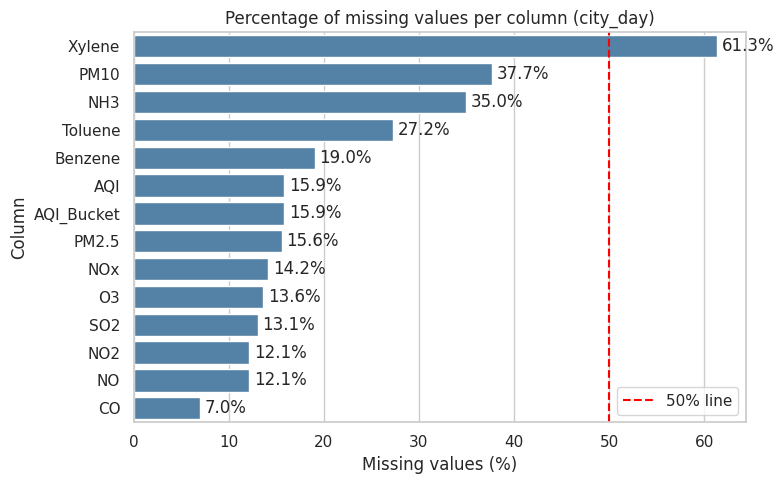

In [6]:
miss = (city.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(8,5))
sns.barplot(x=miss.values, y=miss.index, color='steelblue')
plt.axvline(50, color='red', ls='--', label='50% line')
for i, v in enumerate(miss.values):
    plt.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.xlabel('Missing values (%)'); plt.ylabel('Column')
plt.title('Percentage of missing values per column (city_day)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** Missing data is the biggest problem in most real datasets. We must know *how much* is missing in each column before deciding what to do.
**What it shows:** **Xylene** is missing for about 61% of rows (over the 50% line), **PM10** for about 38% and **NH3** for about 35%. AQI and AQI_Bucket are missing for about 16% of rows. Other pollutants are missing 7–27% (Toluene is the highest of these).

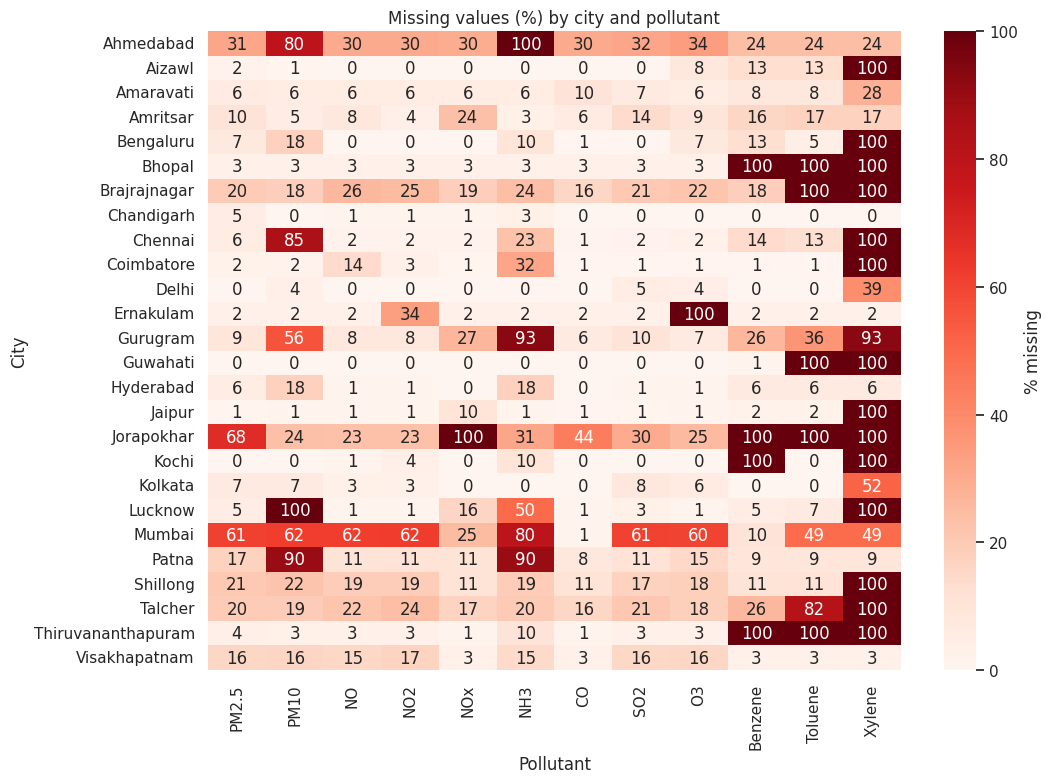

In [7]:
miss_city = city.groupby('City')[POLL].apply(lambda x: x.isna().mean() * 100)
plt.figure(figsize=(11,8))
sns.heatmap(miss_city, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% missing'})
plt.title('Missing values (%) by city and pollutant')
plt.xlabel('Pollutant'); plt.ylabel('City')
plt.tight_layout(); plt.show()

**Why:** Missing values are not always random. If a whole city never measures a pollutant, we need a different fix than for random gaps.
**What it shows:** The gaps are **grouped by city**. 14 of the 26 cities have 100% missing Xylene, and a few cities do not report PM10, NH3, Benzene or Toluene at all. So the missing values come from **stations that do not have that sensor**, not from random errors. This is why we cannot simply fill with one overall average.

## A5. Data quality checks (do the values make sense?)

In [8]:
d = city.dropna(subset=['AQI'])

# 1. Does AQI_Bucket match the AQI number?
bins = [-1, 50, 100, 200, 300, 400, 1e6]
expected = pd.cut(d['AQI'], bins, labels=BUCKETS).astype(str)
print('1. AQI_Bucket not matching AQI :', (expected != d['AQI_Bucket']).sum())

# 2. PM2.5 is a part of PM10, so PM2.5 should not be larger than PM10
both = city.dropna(subset=['PM2.5','PM10'])
bad_pm = (both['PM2.5'] > both['PM10']).sum()
print(f'2. PM2.5 > PM10 (impossible)    : {bad_pm} of {len(both)} rows ({bad_pm/len(both)*100:.1f}%)')

# 3. Negative values
print('3. Negative pollutant values    :', (city[POLL] < 0).sum().sum())

# 4. Very high CO (normal city air is usually below 10 mg/m3)
print('4. Rows with CO > 50            :', (city['CO'] > 50).sum(), '->', city.loc[city['CO'] > 50, 'City'].unique())

1. AQI_Bucket not matching AQI : 0
2. PM2.5 > PM10 (impossible)    : 256 of 17632 rows (1.5%)
3. Negative pollutant values    : 0
4. Rows with CO > 50            : 120 -> <StringArray>
['Ahmedabad']
Length: 1, dtype: str


**Why:** A value can be present and still be wrong. These checks find impossible or suspicious values before we use the data.
**What it shows:**
1. AQI_Bucket always matches AQI, so the label column is reliable.
2. About 1.5% of rows (256) have PM2.5 higher than PM10, which is physically impossible (sensor error). We will **flag** these rows instead of deleting them.
3. There are no negative values.
4. CO above 50 appears **only in Ahmedabad**. This is a red flag and we look at it again in the outlier step.

## A6. Cleaning decisions

**Our 3 cleaning decisions and why:**
1. **Drop rows where AQI is missing.** AQI is the main thing we want to study and predict later. Filling a target value with a guess would create fake answers.
2. **Drop the Xylene column.** About 61% is missing and 14 of 26 cities never measure it. Filling it would be mostly invented data.
3. **Fill the remaining missing pollutants with the median of the same city and same month.** Pollution depends strongly on city and season, so this is more realistic than one overall average. The median is used because it is not affected by extreme values. If a city-month has no data at all, we use the median of that month across all cities.

In [9]:
df = city.copy()

# flag impossible PM values BEFORE imputation (so we do not hide the problem)
df['PM_inconsistent'] = df['PM2.5'] > df['PM10']

# Decision 1: drop rows without AQI
before = len(df)
df = df.dropna(subset=['AQI']).copy()
print(f'Rows dropped (AQI missing): {before - len(df)}  ->  {len(df)} rows remain')

# Decision 2: drop Xylene
df = df.drop(columns=['Xylene'])
POLL_USED = [c for c in POLL if c != 'Xylene']

# month is needed for the imputation step
df['Month'] = df['Date'].dt.month
raw_pm10 = df['PM10'].copy()          # keep a copy to compare later

# Decision 3: fill with city-month median, then month median
for col in POLL_USED:
    df[col] = df[col].fillna(df.groupby(['City','Month'])[col].transform('median'))
    df[col] = df[col].fillna(df.groupby('Month')[col].transform('median'))

print('Missing values left:', df[POLL_USED + ['AQI']].isna().sum().sum())

Rows dropped (AQI missing): 4681  ->  24850 rows remain
Missing values left: 0


**Why:** Most ML models and many statistics cannot work with empty cells, so every missing value must be handled.
**What it shows:** About 4,700 rows without AQI were removed, leaving **24,850 rows**. After filling, **no missing values remain** in the pollutants or AQI.

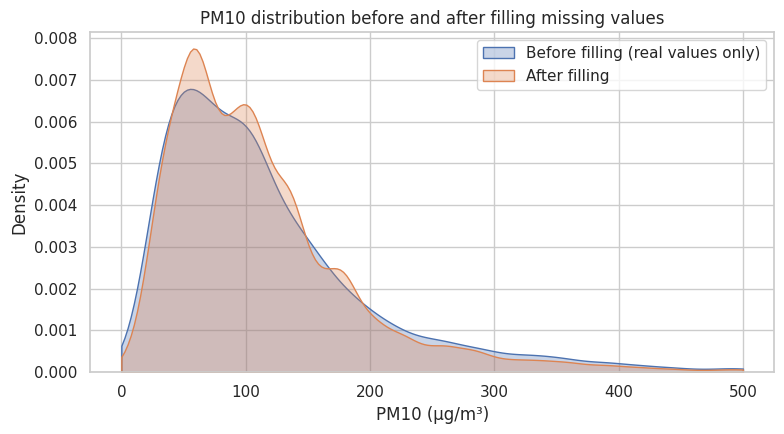

In [10]:
plt.figure(figsize=(8,4.5))
sns.kdeplot(raw_pm10.dropna(), label='Before filling (real values only)', fill=True, alpha=0.3, clip=(0, 500))
sns.kdeplot(df['PM10'], label='After filling', fill=True, alpha=0.3, clip=(0, 500))
plt.xlabel('PM10 (µg/m³)'); plt.ylabel('Density')
plt.title('PM10 distribution before and after filling missing values')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** Filling values should not change the data's overall shape. We check this on PM10, which had the most missing values among the pollutants we kept.
**What it shows:** The two curves have a very similar overall shape and peak, so the filling did **not change the data's pattern**. The filled curve is a little more peaked (many days got the same median value) and has a slightly thinner right tail, so the very extreme PM10 days are under-represented. This is the cost of filling.

## A7. Outliers

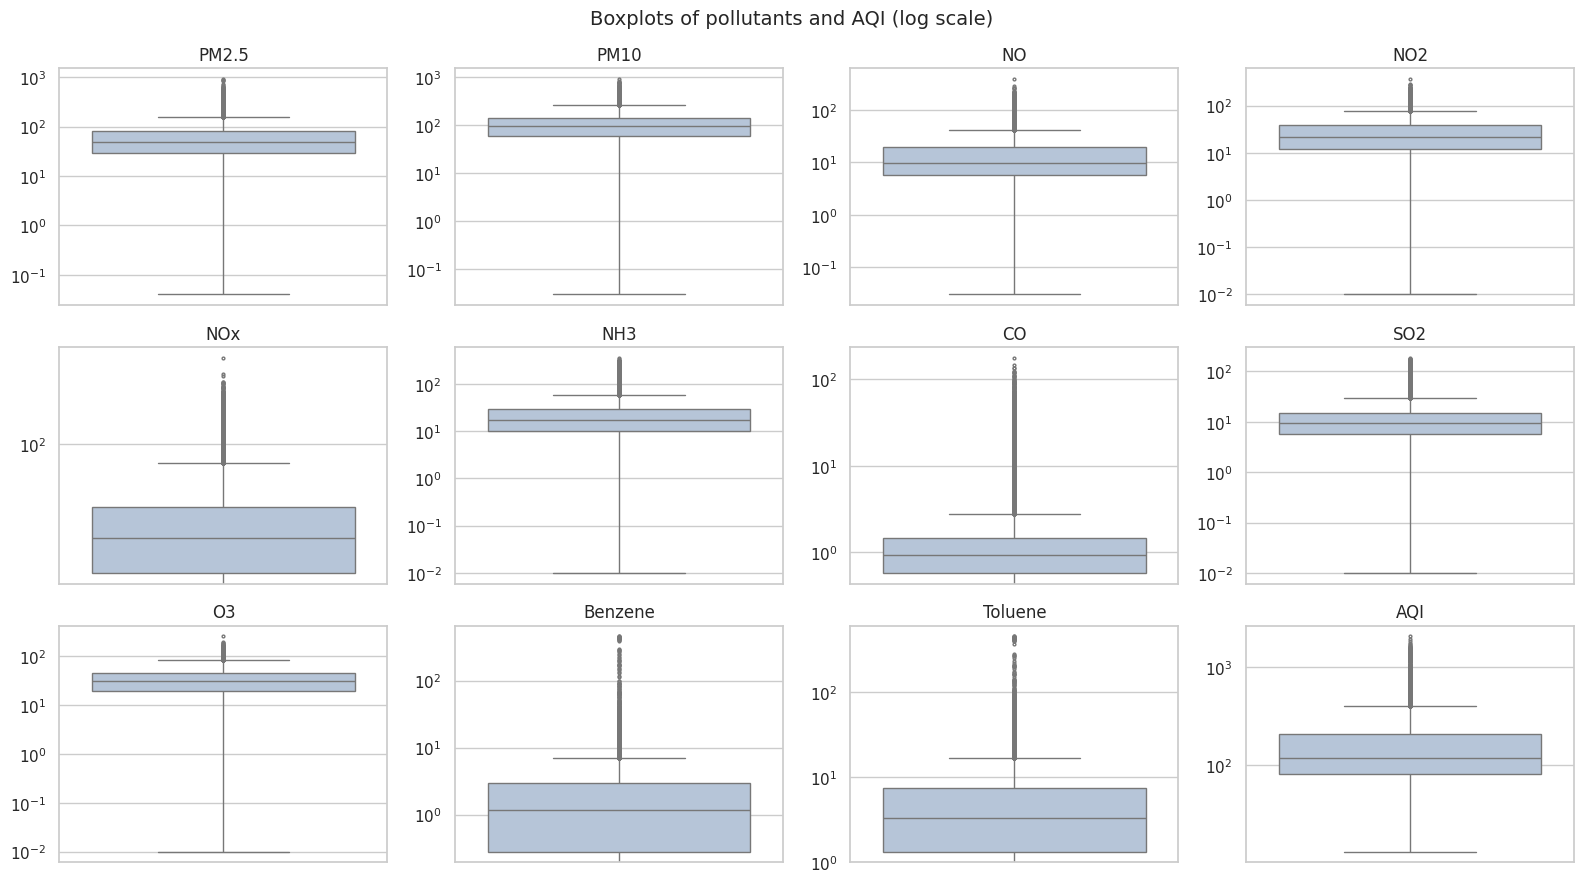

In [11]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, col in zip(axes.ravel(), POLL_USED + ['AQI']):
    sns.boxplot(y=df[col], ax=ax, color='lightsteelblue', flierprops=dict(markersize=2))
    ax.set_yscale('log'); ax.set_title(col); ax.set_ylabel('')
fig.suptitle('Boxplots of pollutants and AQI (log scale)', fontsize=14)
plt.tight_layout(); plt.show()

**Why:** Outliers (very high or very low values) can ruin averages and ML models. A boxplot shows them quickly. A log scale is used so that both small and huge values are visible.
**What it shows:** Every pollutant has many points far above the box, which means the data is **right-skewed**: most days are moderate, a few days are extremely polluted.

In [12]:
iqr_tbl = {}
for col in POLL_USED + ['AQI']:
    q1, q3 = df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((df[col] > q3 + 1.5*iqr) | (df[col] < q1 - 1.5*iqr)).sum()
    iqr_tbl[col] = [n, round(n/len(df)*100, 1)]
pd.DataFrame(iqr_tbl, index=['Outlier count (IQR rule)', 'Outlier %']).T

,Outlier count (IQR rule),Outlier %
PM2.5,1954.0,7.9
PM10,1498.0,6.0
NO,2345.0,9.4
NO2,1103.0,4.4
NOx,1908.0,7.7
NH3,1290.0,5.2
CO,2304.0,9.3
SO2,2490.0,10.0
O3,704.0,2.8
Benzene,1816.0,7.3


**Why:** The IQR rule gives an exact count of outliers instead of just a picture.
**What it shows:** Between about 3% and 13% of values are flagged as outliers, depending on the column. This is too many to be mistakes, so most of them are probably **real pollution events** (e.g. winter smog, Diwali).

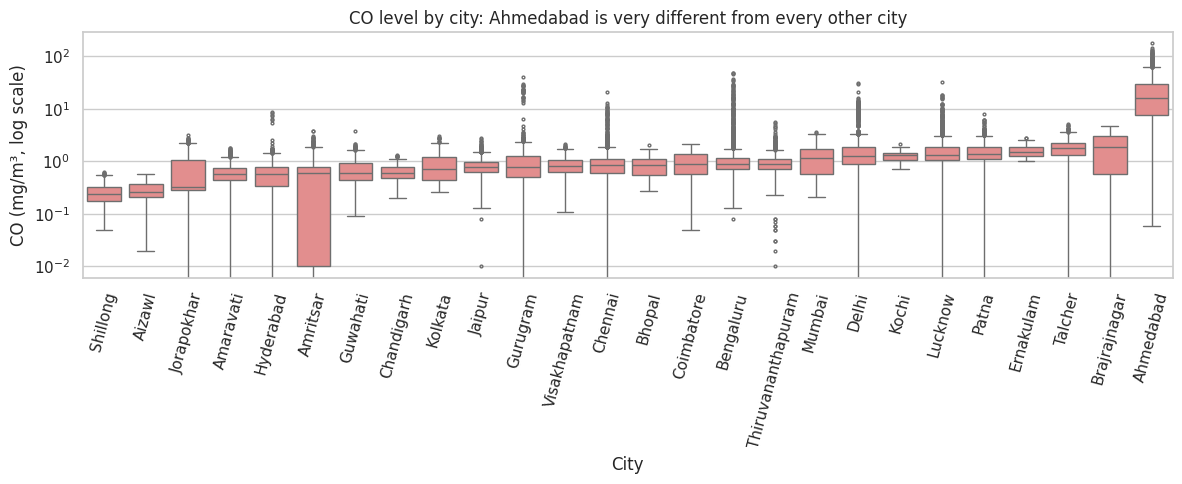

In [13]:
order = df.groupby('City')['CO'].median().sort_values().index
plt.figure(figsize=(12,5))
sns.boxplot(data=df, x='City', y='CO', order=order, color='lightcoral', flierprops=dict(markersize=2))
plt.yscale('log'); plt.xticks(rotation=75)
plt.xlabel('City'); plt.ylabel('CO (mg/m³, log scale)')
plt.title('CO level by city: Ahmedabad is very different from every other city')
plt.tight_layout(); plt.show()

**Why:** Earlier we found CO above 50 only in Ahmedabad. We check whether this is a few bad days or the whole city.
**What it shows:** Ahmedabad's **typical (median) CO is about 16, while other cities are around 1**. So it is not a few errors; the whole Ahmedabad CO record is far higher than the other cities, which may be a measurement or unit problem. AQI depends on the highest pollutant level, so this inflates Ahmedabad's AQI (average about 450 vs about 150 for the rest).

**Decision on outliers:** We **keep** all outliers because most are real pollution events and deleting them would hide the problem we want to study. We only **flag** the Ahmedabad CO issue and the `PM_inconsistent` rows. Later in EDA and in the ML part we will check results **with and without Ahmedabad**, so it does not mislead us.

## A8. Transformation – reduce skewness with log

In [14]:
skew = df[POLL_USED + ['AQI']].skew().round(2)
for col in POLL_USED + ['AQI']:
    df['log_' + col] = np.log1p(df[col])
skew_log = df[['log_' + c for c in POLL_USED + ['AQI']]].skew().round(2)
skew_log.index = skew.index
pd.DataFrame({'Skew (original)': skew, 'Skew (after log)': skew_log})

,Skew (original),Skew (after log)
PM2.5,2.99,0.07
PM10,2.04,-0.47
NO,3.54,0.30
NO2,2.45,-0.36
NOx,2.51,-0.77
NH3,4.33,-0.19
CO,8.69,2.67
SO2,3.93,0.65
O3,1.34,-0.98
Benzene,23.24,1.25


**Why:** Skewed data breaks the assumptions of many statistical tests and models. A log transform (`log1p`) pulls the long right tail in.
**What it shows:** Original skewness is high for most columns (above 2 for most, and extreme for CO at 8.7 and Benzene at 23). After the log transform it falls to between -1 and 1 for almost all columns, so the data is much more balanced. CO (2.7) and Benzene (1.3) are still skewed, mainly because of the Ahmedabad values. We keep both versions: the original for easy reading and the `log_` version for tests and models.

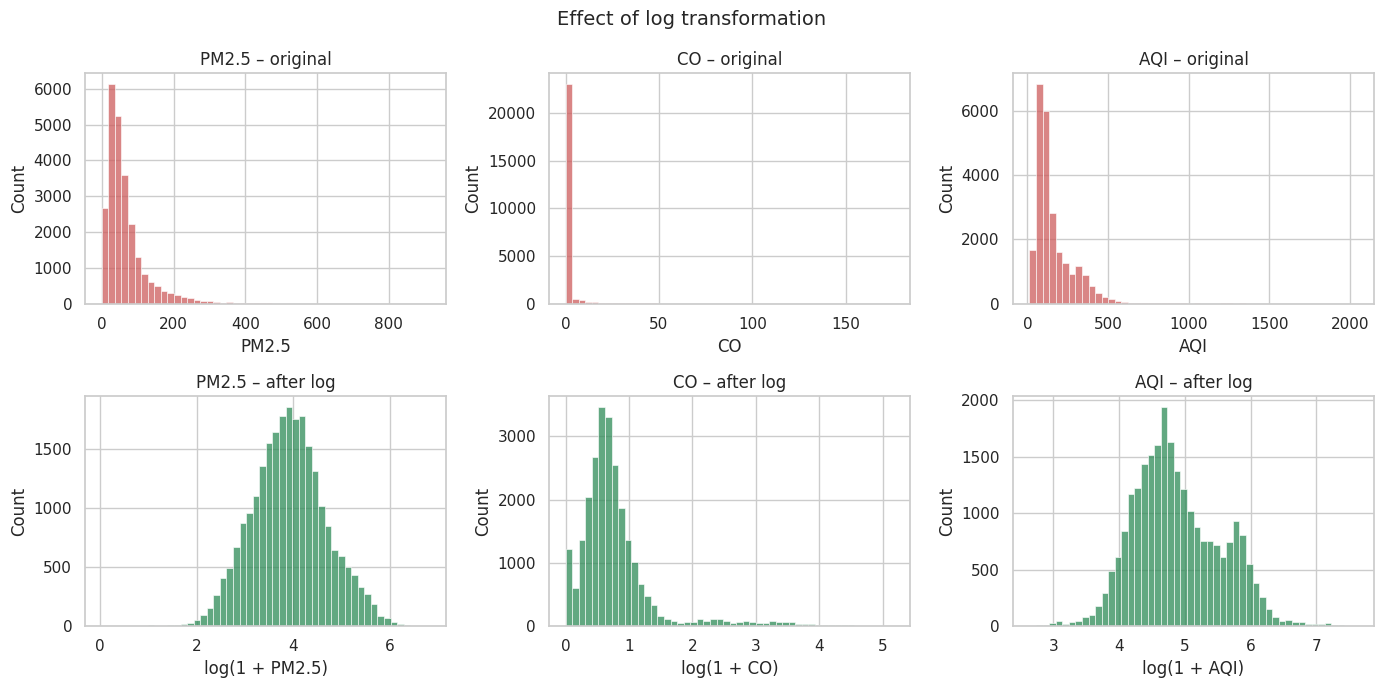

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, col in enumerate(['PM2.5', 'CO', 'AQI']):
    sns.histplot(df[col], bins=50, ax=axes[0, j], color='indianred'); axes[0, j].set_title(f'{col} – original')
    sns.histplot(df['log_' + col], bins=50, ax=axes[1, j], color='seagreen'); axes[1, j].set_title(f'{col} – after log')
    axes[0, j].set_xlabel(col); axes[1, j].set_xlabel('log(1 + ' + col + ')')
plt.suptitle('Effect of log transformation', fontsize=14)
plt.tight_layout(); plt.show()

**Why:** A picture proves the log transform worked.
**What it shows:** The top row has a tall spike near zero and a very long tail. The bottom row is a smooth, roughly bell-shaped curve. The log version is better for statistics and modelling.

## A9. Feature engineering (new useful columns)

In [16]:
df['Year']      = df['Date'].dt.year
df['DayOfWeek'] = df['Date'].dt.day_name()
df['IsWeekend'] = df['Date'].dt.dayofweek >= 5

def season(m):
    if m in (12, 1, 2): return 'Winter'
    if m in (3, 4, 5):  return 'Summer'
    if m in (6, 7, 8, 9): return 'Monsoon'
    return 'Post-Monsoon'
df['Season'] = df['Month'].apply(season)

# COVID-19 lockdown in India started on 25 March 2020
df['Lockdown'] = np.where(df['Date'] >= '2020-03-25', 'Lockdown', 'Before lockdown')

# State from stations.csv
city_state = stations.drop_duplicates('City').set_index('City')['State']
df['State'] = df['City'].map(city_state)

region = {
 'North': ['Delhi','Gurugram','Chandigarh','Amritsar','Jaipur','Lucknow'],
 'South': ['Bengaluru','Chennai','Hyderabad','Amaravati','Visakhapatnam','Coimbatore','Thiruvananthapuram','Ernakulam','Kochi'],
 'East': ['Kolkata','Patna','Jorapokhar','Brajrajnagar','Talcher'],
 'West': ['Ahmedabad','Mumbai'],
 'Central': ['Bhopal'],
 'North-East': ['Guwahati','Shillong','Aizawl']}
city_region = {c: r for r, cs in region.items() for c in cs}
df['Region'] = df['City'].map(city_region)

df = df.sort_values(['City', 'Date']).reset_index(drop=True)
print('Cities without State :', df['State'].isna().sum(), '| without Region:', df['Region'].isna().sum())
df[['City','Date','Year','Month','Season','Region','State','Lockdown','AQI','AQI_Bucket']].head()

Cities without State : 0 | without Region: 0


,City,Date,Year,Month,Season,Region,State,Lockdown,AQI,AQI_Bucket
0,Ahmedabad,2015-01-29,2015,1,Winter,West,Gujarat,Before lockdown,209.0,Poor
1,Ahmedabad,2015-01-30,2015,1,Winter,West,Gujarat,Before lockdown,328.0,Very Poor
2,Ahmedabad,2015-01-31,2015,1,Winter,West,Gujarat,Before lockdown,514.0,Severe
3,Ahmedabad,2015-02-01,2015,2,Winter,West,Gujarat,Before lockdown,782.0,Severe
4,Ahmedabad,2015-02-02,2015,2,Winter,West,Gujarat,Before lockdown,914.0,Severe


**Why:** The raw file only has a date and a city. Pollution depends on **season, year, region and special events**, so we create these columns to be able to study them.
**What it shows:** We added Year, Month, Season (Indian seasons), Weekend flag, Lockdown flag (from 25 Mar 2020), State and Region. Every city got a State and Region (0 missing).

## A10. Station data – merge and clean

In [17]:
sd = station.merge(stations, on='StationId', how='left')
print('Stations in station_day :', station['StationId'].nunique())
print('Stations with no match in stations.csv :', sd['StationName'].isna().sum(), 'rows')
print('Rows without AQI :', sd['AQI'].isna().sum(), f"({sd['AQI'].isna().mean()*100:.1f}%)")
sd = sd.dropna(subset=['AQI']).copy()
sd['Year'] = sd['Date'].dt.year
print('Station rows after dropping missing AQI :', len(sd))

Stations in station_day : 110
Stations with no match in stations.csv : 0 rows
Rows without AQI : 21010 (19.4%)
Station rows after dropping missing AQI : 87025


**Why:** `station_day.csv` only has station codes. Joining it with `stations.csv` gives each reading a city and state, so we can compare states later. We drop rows with missing AQI for the same reason as before.
**What it shows:** Every station code matched (no unmatched rows). About 19% of station rows have no AQI and are dropped. We use this file only for state-level views, and `city_day` stays the main dataset.

## A11. Save the clean data

In [18]:
df.to_csv('city_day_clean.csv', index=False)
sd.to_csv('station_day_clean.csv', index=False)
print('Clean city data   :', df.shape)
print('Clean station data:', sd.shape)
print('Missing values in clean city data:', df[POLL_USED + ['AQI']].isna().sum().sum())

Clean city data   : (24850, 36)
Clean station data: (87025, 21)
Missing values in clean city data: 0


**Why:** Saving the clean files lets the next parts (hypothesis testing, ML, Power BI/Tableau) start from clean data without repeating these steps.
**What it shows:** The final city dataset has about 24,850 rows and 0 missing values in pollutants and AQI.

# PART B – EXPLORATORY DATA ANALYSIS (EDA)

## B1. Summary statistics

In [19]:
stats = df[POLL_USED + ['AQI']].describe().T.round(2)
stats['skew'] = df[POLL_USED + ['AQI']].skew().round(2)
stats

,count,mean,std,min,25%,50%,75%,max,skew
PM2.5,24850.0,66.85,62.45,0.04,28.94,48.40,80.26,914.94,2.99
PM10,24850.0,113.84,80.94,0.03,59.01,95.26,139.31,917.08,2.04
NO,24850.0,17.57,22.28,0.03,5.70,9.94,20.04,390.68,3.54
NO2,24850.0,28.78,24.52,0.01,11.87,21.91,37.98,362.21,2.45
NOx,24850.0,31.77,29.69,0.00,13.81,23.79,38.37,378.24,2.51
NH3,24850.0,23.06,23.30,0.01,9.94,17.48,29.19,352.89,4.33
CO,24850.0,2.32,7.02,0.00,0.58,0.93,1.47,175.81,8.69
SO2,24850.0,14.42,17.39,0.01,5.77,9.26,15.16,186.08,3.93
O3,24850.0,34.71,21.52,0.01,19.25,31.08,45.66,257.73,1.34
Benzene,24850.0,3.14,14.88,0.00,0.28,1.16,2.94,455.03,23.24


**Why:** Summary statistics give a quick numeric picture of each column: centre, spread and extremes.
**What it shows:** For every pollutant the **mean is higher than the median** and the maximum is far above the 75th percentile. This again says a few very polluted days pull the average up. The average AQI is about 166 (Moderate), but the median is lower (about 118), so the **median is a fairer 'typical day'** than the mean.

## B2. Univariate analysis (one column at a time)

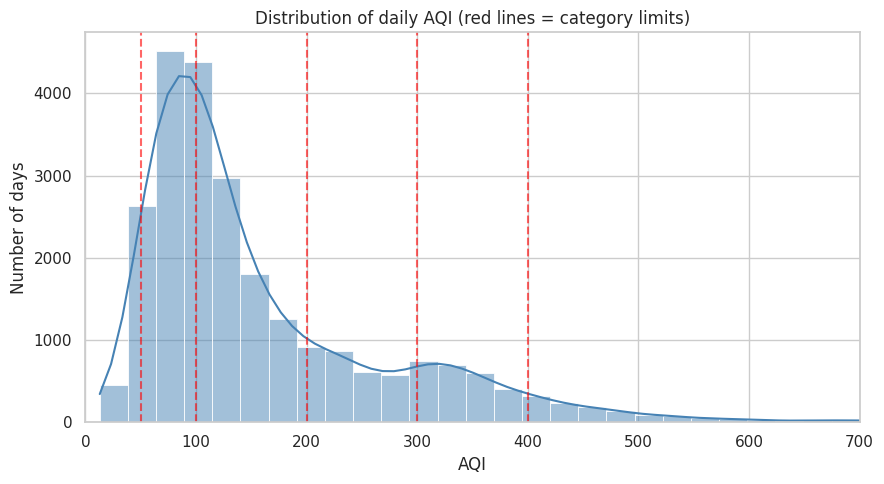

Days with AQI above 700 (not shown): 216


In [20]:
plt.figure(figsize=(9,5))
sns.histplot(df['AQI'], bins=80, kde=True, color='steelblue')
for x in [50, 100, 200, 300, 400]:
    plt.axvline(x, color='red', ls='--', alpha=.6)
plt.xlim(0, 700)
plt.xlabel('AQI'); plt.ylabel('Number of days')
plt.title('Distribution of daily AQI (red lines = category limits)')
plt.tight_layout(); plt.show()
print('Days with AQI above 700 (not shown):', (df['AQI'] > 700).sum())

**Why:** AQI is our main variable, so we must understand its shape first.
**What it shows:** Most days fall between 50 and 200 (Satisfactory to Moderate). The curve has a **long tail to the right**: a smaller number of days go above 300 and some above 500. There are no very clean days; very few days are below 50.

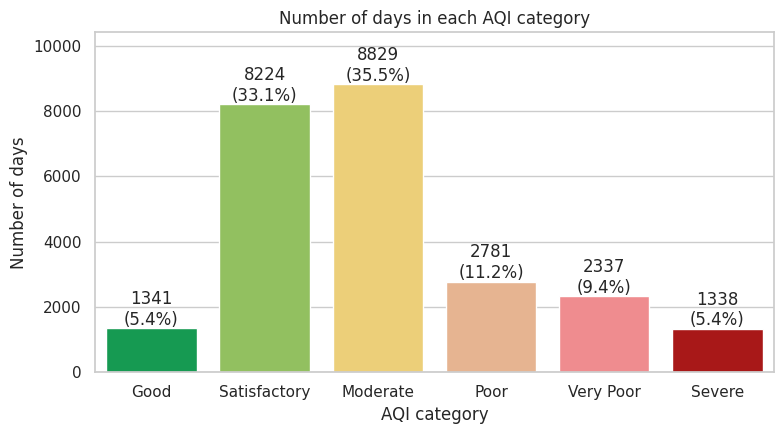

In [21]:
cnt = df['AQI_Bucket'].value_counts().reindex(BUCKETS)
colors = ['#00b050','#92d050','#ffd966','#f4b183','#ff7c80','#c00000']
plt.figure(figsize=(8,4.5))
ax = sns.barplot(x=cnt.index, y=cnt.values, palette=colors)
for i, v in enumerate(cnt.values):
    ax.text(i, v + 100, f'{v}\n({v/len(df)*100:.1f}%)', ha='center')
plt.xlabel('AQI category'); plt.ylabel('Number of days')
plt.title('Number of days in each AQI category')
plt.ylim(0, cnt.max() * 1.18); plt.tight_layout(); plt.show()

**Why:** The government groups AQI into health categories. Counting days in each category is easier to understand than raw numbers, and it shows if the classes are balanced (important if we classify later).
**What it shows:** **Moderate (35%)** and **Satisfactory (33%)** are the biggest groups. Only about 5% of days are Good, while about 15% are Very Poor or Severe. The classes are **not equal in size**, so accuracy alone would be misleading if we build a classifier later.

## B3. Bivariate analysis (two columns together)

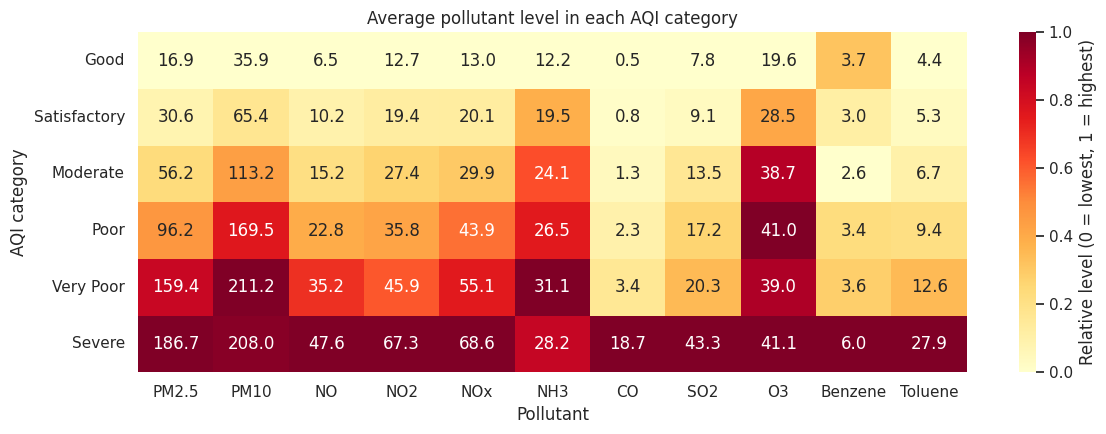

In [22]:
profile = df.groupby('AQI_Bucket')[POLL_USED].mean().reindex(BUCKETS)
scaled = (profile - profile.min()) / (profile.max() - profile.min())
plt.figure(figsize=(12,4.5))
sns.heatmap(scaled, annot=profile.round(1), fmt='', cmap='YlOrRd', cbar_kws={'label': 'Relative level (0 = lowest, 1 = highest)'})
plt.xlabel('Pollutant'); plt.ylabel('AQI category')
plt.title('Average pollutant level in each AQI category')
plt.tight_layout(); plt.show()

**Why:** This tells us which pollutants go up when air gets worse. Numbers in the boxes are real averages; colours are scaled so each column can be compared.
**What it shows:** **PM2.5 rises steadily** from 17 (Good) to 187 (Severe), and PM10 rises up to Very Poor. NO, NO2 and NOx also go up with worse air. **CO stays low (0.5–3.4) until the Severe group, where it suddenly jumps to 18.7**; this jump is caused by Ahmedabad, not by all cities. Benzene and O3 do not follow AQI in a clear way.

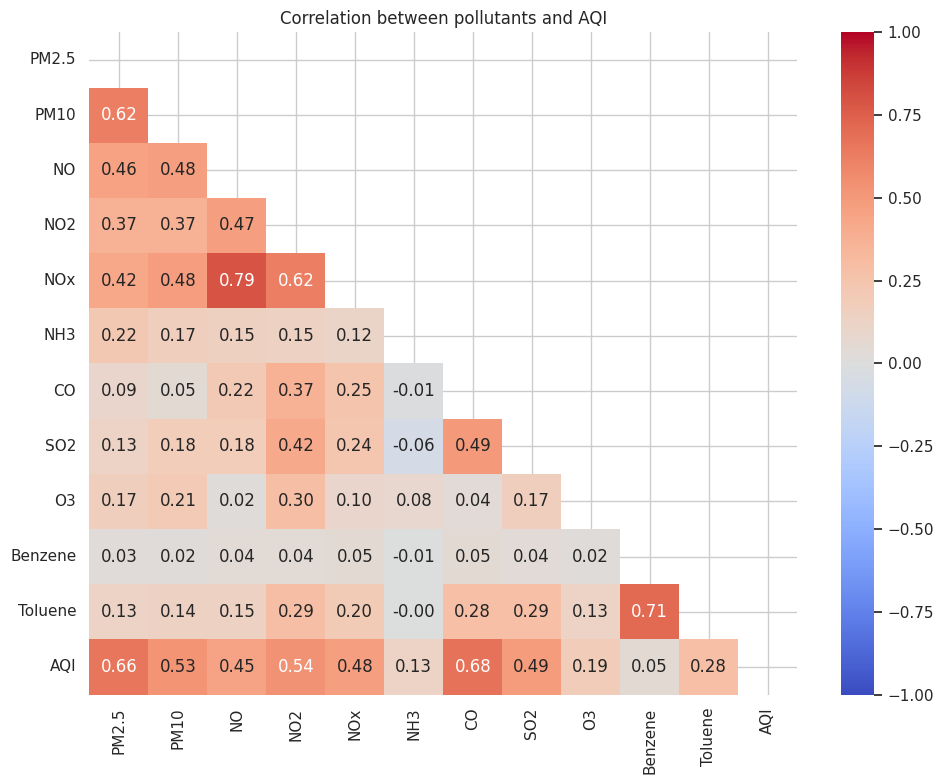

In [23]:
corr = df[POLL_USED + ['AQI']].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(10,8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation between pollutants and AQI')
plt.tight_layout(); plt.show()

**Why:** Correlation shows which pollutants move with AQI (useful for choosing features) and which move with each other (a problem called multicollinearity for regression).
**What it shows:** AQI is most correlated with **CO (0.68) and PM2.5 (0.66)**, then NO2, PM10, SO2 and NOx (about 0.5). O3 (0.19), NH3 (0.13) and Benzene (0.05) are weak. **NOx moves closely with NO and NO2** (NOx is made from them), and PM2.5 moves with PM10, so using all of them together in a regression would repeat the same information. We should select features carefully later. The next chart checks if these numbers are reliable.

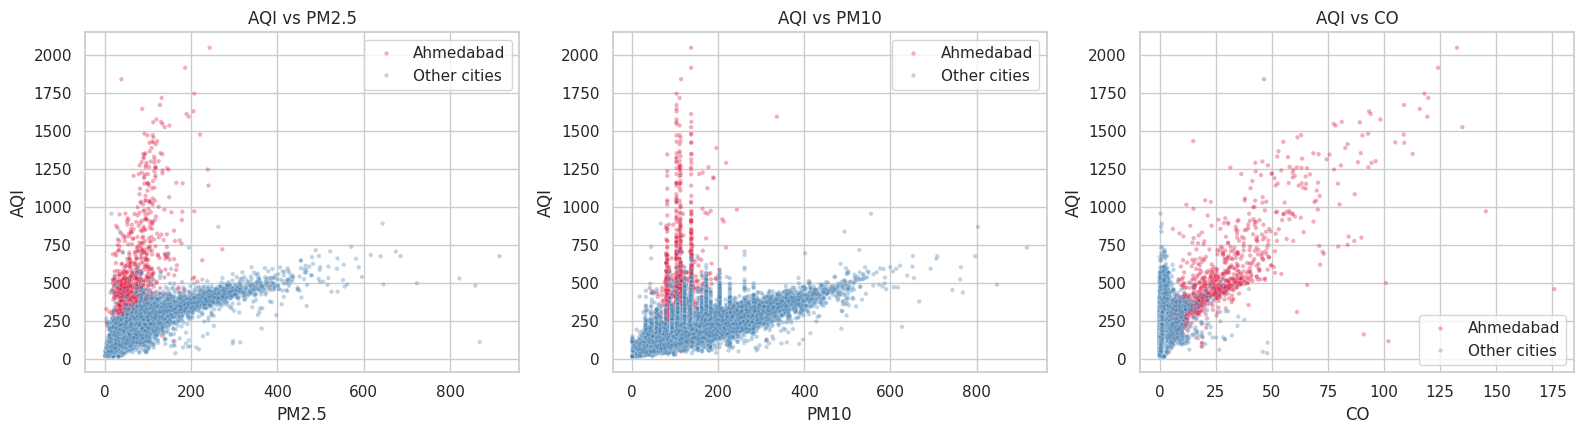

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
is_ahd = np.where(df['City'] == 'Ahmedabad', 'Ahmedabad', 'Other cities')
for ax, col in zip(axes, ['PM2.5', 'PM10', 'CO']):
    sns.scatterplot(x=df[col], y=df['AQI'], hue=is_ahd, alpha=.35, s=10, ax=ax,
                    palette={'Ahmedabad': 'crimson', 'Other cities': 'steelblue'})
    ax.set_xlabel(col); ax.set_ylabel('AQI'); ax.set_title(f'AQI vs {col}')
plt.tight_layout(); plt.show()

**Why:** Correlation is one number; a scatter plot shows the real shape of the relationship and whether one group behaves differently.
**What it shows:** For the other cities (blue), AQI rises in an almost straight line with PM2.5 and PM10, so these are strong, clean relationships. **Ahmedabad (red) sits far above this line**: its AQI is very high even when PM is moderate, and in the CO plot it forms its own rising cloud. This confirms Ahmedabad behaves differently and should be handled separately. The vertical stripes in the PM10 plot are rows where PM10 was filled with the same median value (a side effect of filling).

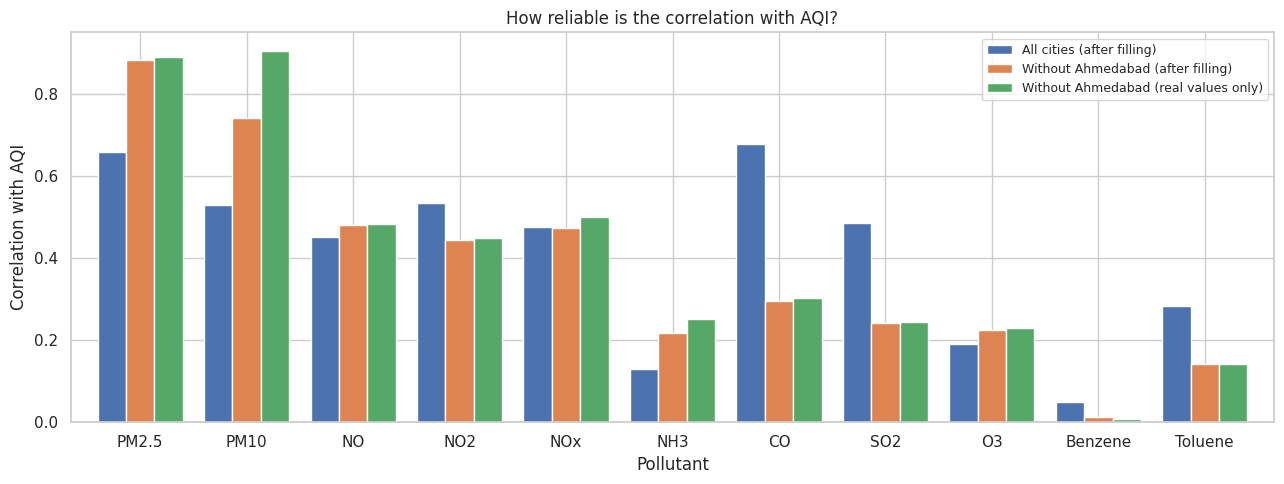

,All cities (after filling),Without Ahmedabad (after filling),Without Ahmedabad (real values only)
PM2.5,0.66,0.88,0.89
PM10,0.53,0.74,0.90
NO,0.45,0.48,0.48
NO2,0.54,0.44,0.45
NOx,0.48,0.47,0.50
NH3,0.13,0.22,0.25
CO,0.68,0.30,0.30
SO2,0.49,0.24,0.24
O3,0.19,0.22,0.23
Benzene,0.05,0.01,0.01


In [25]:
raw = city.dropna(subset=['AQI'])
cmp = pd.DataFrame({
    'All cities (after filling)':           df[POLL_USED + ['AQI']].corr()['AQI'],
    'Without Ahmedabad (after filling)':    df[df['City'] != 'Ahmedabad'][POLL_USED + ['AQI']].corr()['AQI'],
    'Without Ahmedabad (real values only)': raw[raw['City'] != 'Ahmedabad'][POLL_USED + ['AQI']].corr()['AQI'],
}).drop('AQI')
cmp.plot(kind='bar', figsize=(13,5), width=.8)
plt.axhline(0, color='k', lw=.8)
plt.ylabel('Correlation with AQI'); plt.xlabel('Pollutant'); plt.xticks(rotation=0)
plt.title('How reliable is the correlation with AQI?')
plt.legend(loc='upper right', fontsize=9); plt.tight_layout(); plt.show()
cmp.round(2)

**Why:** We should never trust a correlation without checking if it is stable. Here we compare 3 versions: all cities, without Ahmedabad, and without Ahmedabad using only real (not filled) values.
**What it shows:** Two important things. **(1) CO's correlation drops from 0.68 to 0.30 when Ahmedabad is removed**, so CO looked important only because of Ahmedabad. **(2) PM2.5 and PM10 are the true main drivers of AQI** (about 0.89 and 0.90 with real values). Filling the 38% missing PM10 values weakened its correlation from 0.90 to 0.74, which shows how filling can hide a strong relationship.

## B4. Data coverage – is the data balanced?

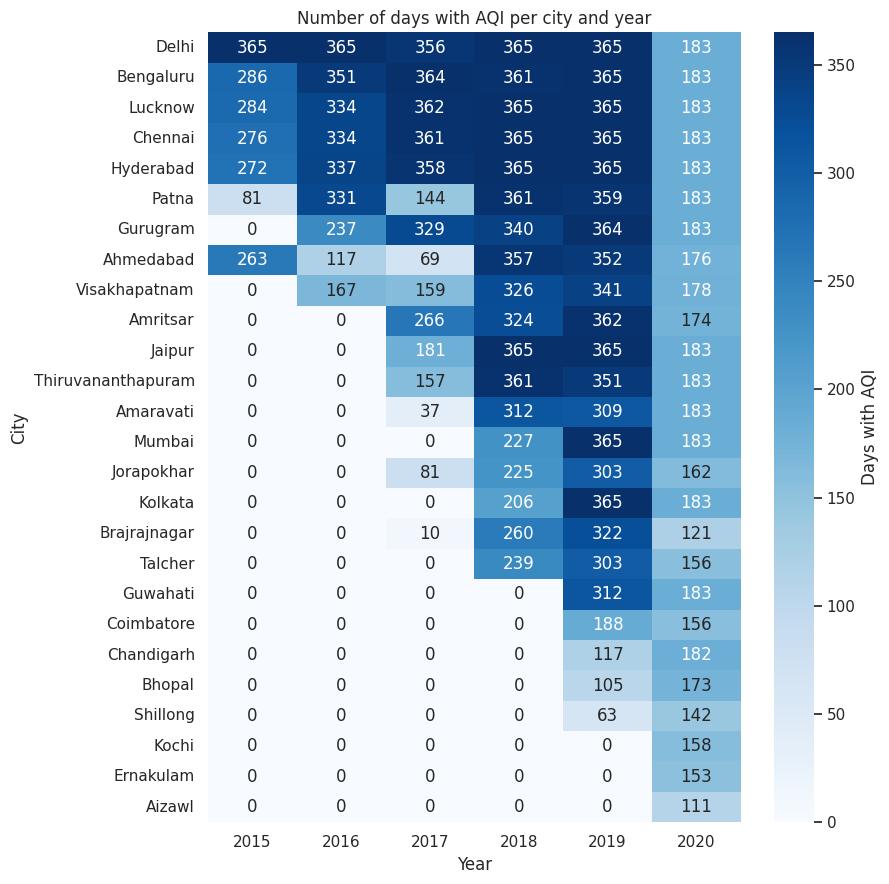

In [26]:
cov = df.pivot_table(index='City', columns='Year', values='AQI', aggfunc='count').fillna(0).astype(int)
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).index]
plt.figure(figsize=(9,9))
sns.heatmap(cov, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Days with AQI'})
plt.title('Number of days with AQI per city and year')
plt.xlabel('Year'); plt.ylabel('City')
plt.tight_layout(); plt.show()

**Why:** Before comparing cities or years we must check that each has enough and similar amounts of data. If not, comparisons can be unfair.
**What it shows:** The data is **very unbalanced**. Only a few cities (Delhi, Ahmedabad, Lucknow, Bengaluru, Chennai, Hyderabad) have data from 2015. Many cities start in 2018–2020, and some (Aizawl, Ernakulam, Kochi) have only a few months. Also 2020 has only half a year. So yearly trends must be read carefully.

## B5. City-wise analysis

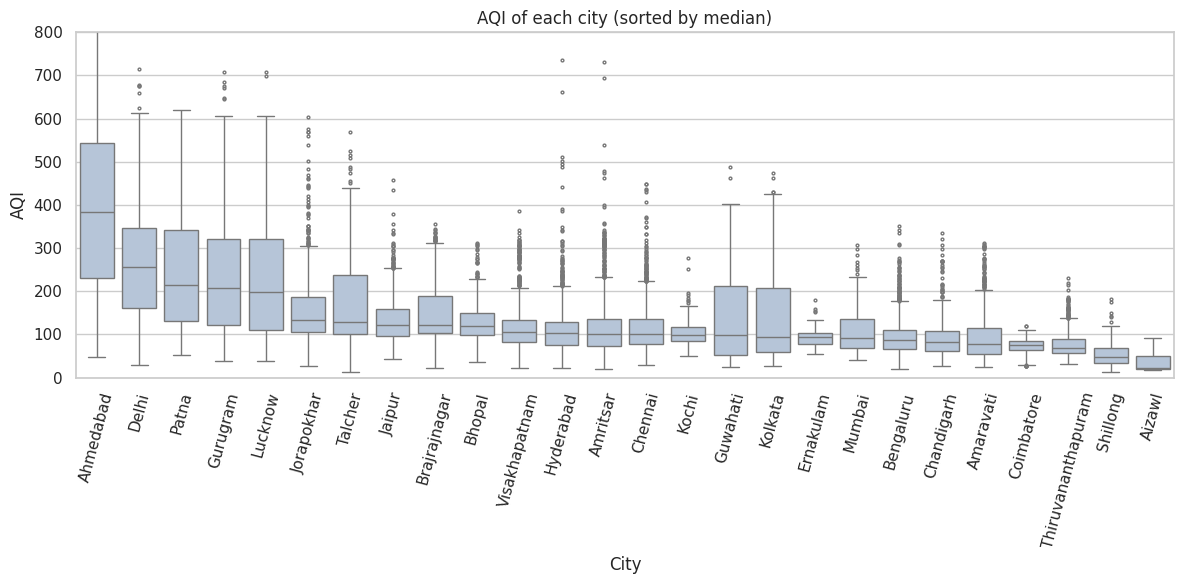

In [27]:
order = df.groupby('City')['AQI'].median().sort_values(ascending=False).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x='City', y='AQI', order=order, color='lightsteelblue', flierprops=dict(markersize=2))
plt.ylim(0, 800); plt.xticks(rotation=75)
plt.xlabel('City'); plt.ylabel('AQI')
plt.title('AQI of each city (sorted by median)')
plt.tight_layout(); plt.show()

**Why:** This answers the basic question "which cities are the most polluted?" and also shows how much AQI varies within each city.
**What it shows:** **Ahmedabad** is at the top by a large margin (affected by the CO issue). After it, **Delhi, Patna, Gurugram and Lucknow** have the highest AQI. **Aizawl, Shillong, Coimbatore and Thiruvananthapuram** are the cleanest. North Indian cities also have wide boxes, meaning their air quality changes a lot from day to day.

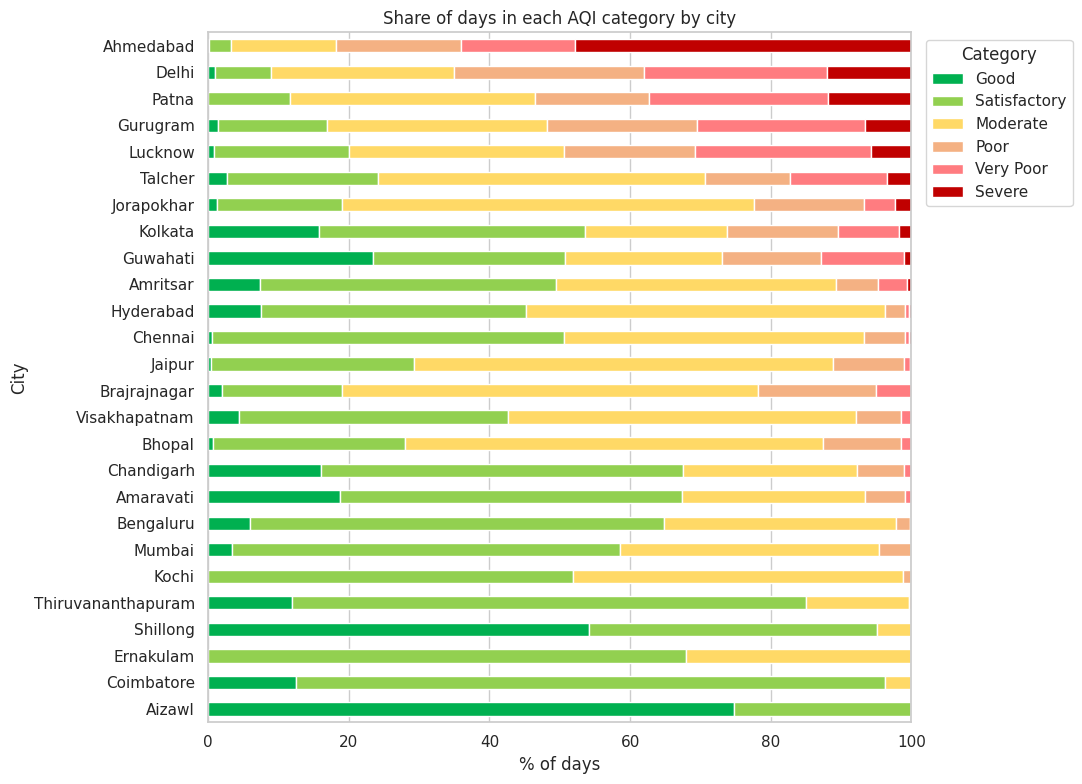

In [28]:
share = pd.crosstab(df['City'], df['AQI_Bucket'], normalize='index')[BUCKETS] * 100
share = share.sort_values(['Severe', 'Very Poor', 'Poor'], ascending=True)
share.plot(kind='barh', stacked=True, figsize=(11,8), color=colors)
plt.xlabel('% of days'); plt.ylabel('City')
plt.title('Share of days in each AQI category by city')
plt.legend(title='Category', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout(); plt.show()

**Why:** An average can hide how often a city has dangerous days. This chart shows the share of days in each category.
**What it shows:** Ahmedabad is mostly Severe. Delhi, Patna, Gurugram and Lucknow have a large share of Poor, Very Poor and Severe days. Southern and north-eastern cities are almost entirely Good or Satisfactory.

## B6. Time-based analysis

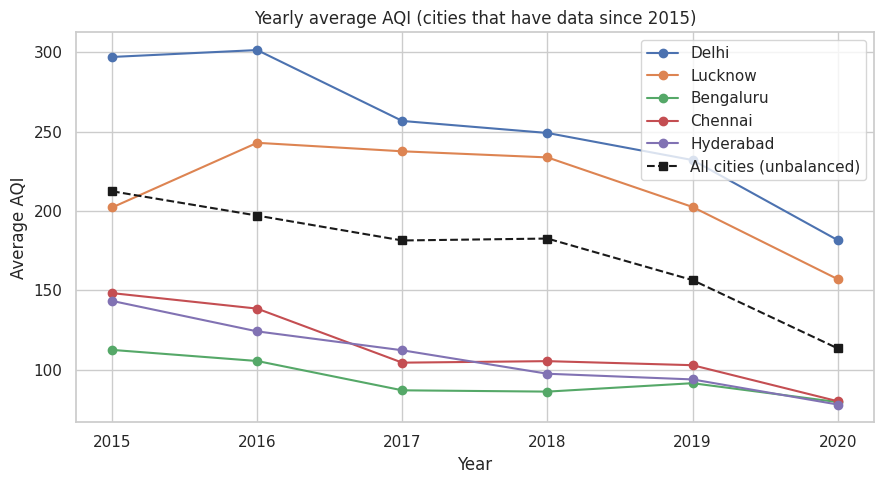

In [29]:
top5 = ['Delhi', 'Lucknow', 'Bengaluru', 'Chennai', 'Hyderabad']
yr = df[df['City'].isin(top5)].pivot_table(index='Year', columns='City', values='AQI', aggfunc='mean')
plt.figure(figsize=(9,5))
for c in top5:
    plt.plot(yr.index, yr[c], marker='o', label=c)
plt.plot(df.groupby('Year')['AQI'].mean(), 'k--', marker='s', label='All cities (unbalanced)')
plt.xlabel('Year'); plt.ylabel('Average AQI')
plt.title('Yearly average AQI (cities that have data since 2015)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** We want to know if air quality is getting better or worse over time. We use cities with data from the start so the comparison is fair. The black line (all cities) is shown only for comparison, because the set of cities changes every year.
**What it shows:** Delhi and Lucknow stay at a high level but slowly improve after 2016 (Delhi falls from about 300 to about 180), while Bengaluru, Chennai and Hyderabad are much lower and also fall. The **all-cities line falls sharply**, but part of this fall is only because many clean southern/north-eastern cities were added later. 2020 is lower for most cities.

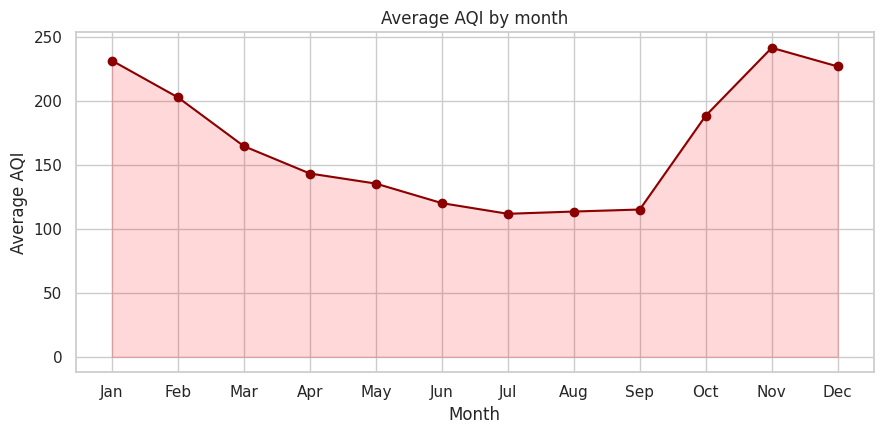

In [30]:
m = df.groupby('Month')['AQI'].mean()
plt.figure(figsize=(9,4.5))
plt.plot(m.index, m.values, marker='o', color='darkred')
plt.fill_between(m.index, m.values, alpha=.15, color='red')
plt.xticks(range(1,13), ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.title('Average AQI by month')
plt.tight_layout(); plt.show()

**Why:** Pollution usually follows the weather, so we check the monthly pattern.
**What it shows:** A clear **U-shape**: AQI is highest in **November (about 240), December and January** and lowest in **July–September (about 112–115)**. Rain in the monsoon washes pollutants out of the air; in winter, cold air traps them near the ground, and crop burning and Diwali add more.

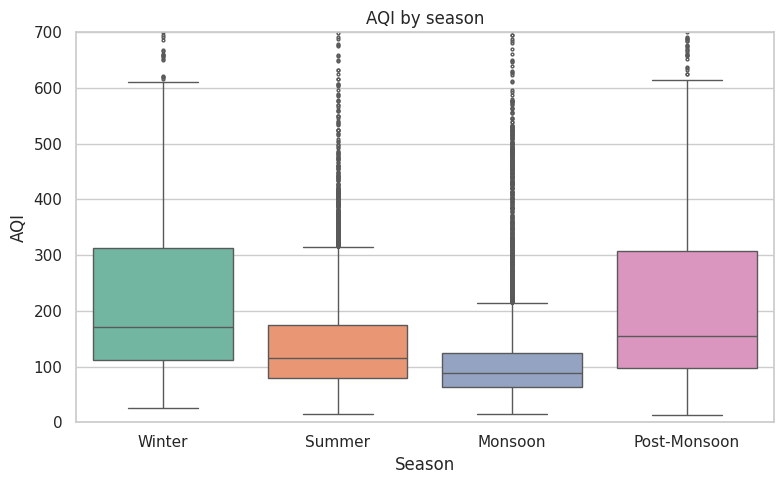

               mean  median
Season                     
Winter        221.0   171.0
Summer        148.0   115.0
Monsoon       116.0    89.0
Post-Monsoon  215.0   154.0


In [31]:
order_s = ['Winter', 'Summer', 'Monsoon', 'Post-Monsoon']
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='Season', y='AQI', order=order_s, palette='Set2', flierprops=dict(markersize=2))
plt.ylim(0, 700)
plt.xlabel('Season'); plt.ylabel('AQI')
plt.title('AQI by season')
plt.tight_layout(); plt.show()
print(df.groupby('Season')['AQI'].agg(['mean','median']).round(0).reindex(order_s))

**Why:** Grouping 12 months into 4 seasons makes the comparison simpler and gives us a clean categorical column for hypothesis testing later.
**What it shows:** **Winter (average about 221) and Post-Monsoon (about 215)** have the highest AQI and the widest spread. **Monsoon (about 116)** is the cleanest season with the smallest spread. Season is clearly an important factor.

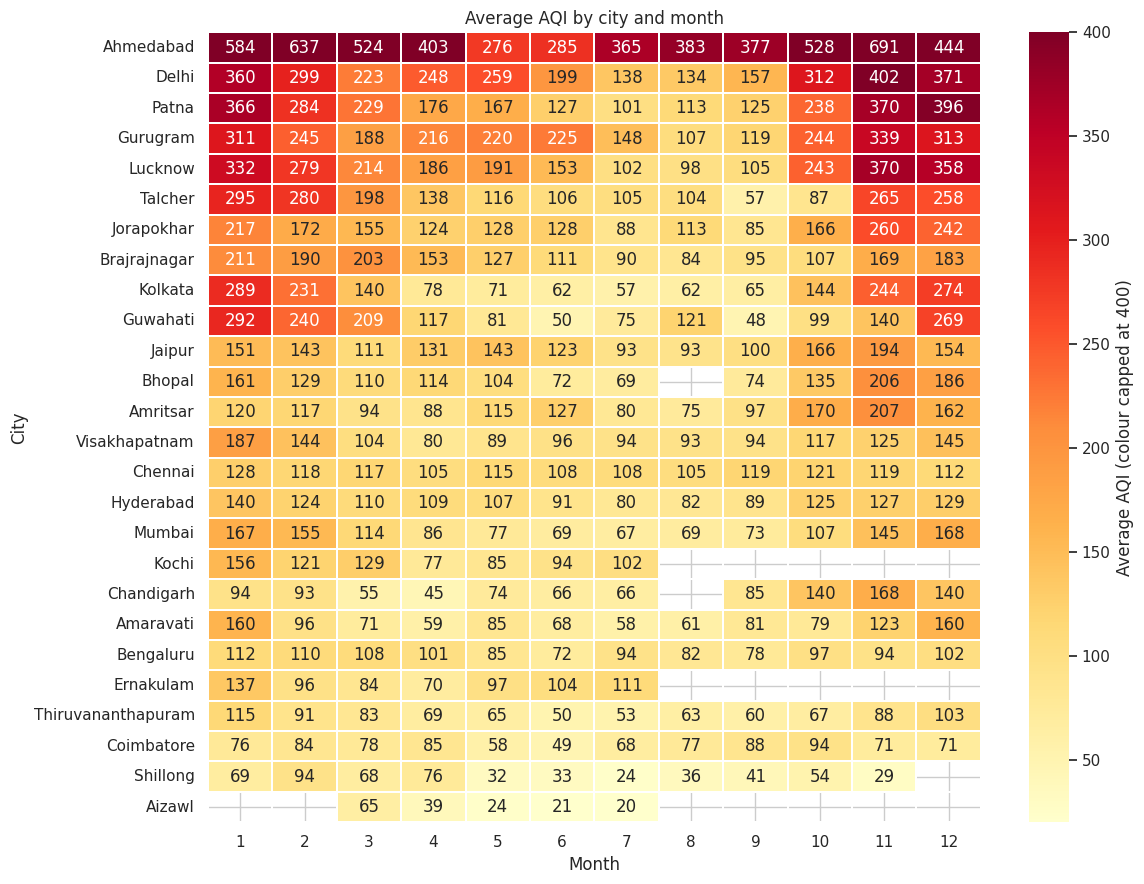

In [32]:
heat = df.pivot_table(index='City', columns='Month', values='AQI', aggfunc='mean')
heat = heat.loc[df.groupby('City')['AQI'].mean().sort_values(ascending=False).index]
plt.figure(figsize=(12,9))
sns.heatmap(heat, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=.3, vmax=400, cbar_kws={'label': 'Average AQI (colour capped at 400)'})
plt.xlabel('Month'); plt.ylabel('City')
plt.title('Average AQI by city and month')
plt.tight_layout(); plt.show()

**Why:** This combines the two ideas (city and month) to see if the seasonal pattern is the same everywhere.
**What it shows:** Ahmedabad is the darkest city almost all year. Among the others, the north Indian cities (Delhi, Patna, Gurugram, Lucknow) are darkest in **Nov–Jan (about 300–400)** and much lighter in Jul–Sep (about 100–150). Southern and north-eastern cities stay light and fairly flat, mostly below about 130. So **season matters mostly in the north and east**. Empty cells are months where the city has no data.

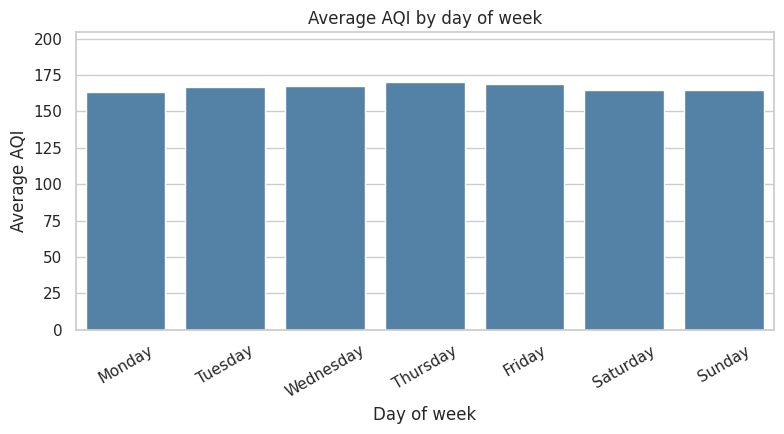

In [33]:
dow = df.groupby('DayOfWeek')['AQI'].mean().reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
plt.figure(figsize=(8,4.5))
sns.barplot(x=dow.index, y=dow.values, color='steelblue')
plt.ylim(0, dow.max() * 1.2); plt.xticks(rotation=30)
plt.xlabel('Day of week'); plt.ylabel('Average AQI')
plt.title('Average AQI by day of week')
plt.tight_layout(); plt.show()

**Why:** We test an idea: is air cleaner on weekends because there is less traffic and industry?
**What it shows:** The bars are almost the same height (average AQI between 164 and 170 on every day). **Day of week has very little effect on AQI.** This is useful because it tells us this feature will probably not help a model, so we can leave it out.

## B7. Region analysis

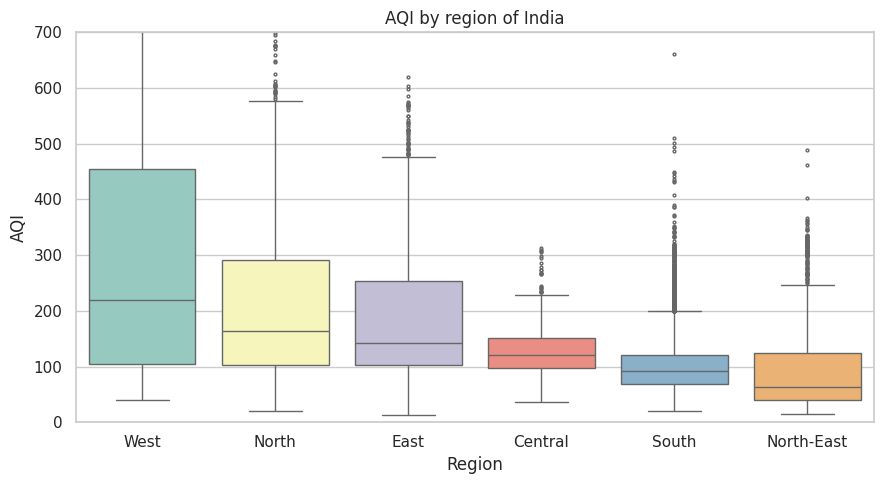

In [34]:
order_r = df.groupby('Region')['AQI'].median().sort_values(ascending=False).index
plt.figure(figsize=(9,5))
sns.boxplot(data=df, x='Region', y='AQI', order=order_r, palette='Set3', flierprops=dict(markersize=2))
plt.ylim(0, 700)
plt.xlabel('Region'); plt.ylabel('AQI')
plt.title('AQI by region of India')
plt.tight_layout(); plt.show()

**Why:** Grouping 26 cities into 6 regions makes the picture simpler and lets us test regional differences later.
**What it shows:** **West (because of Ahmedabad) and North** have the highest AQI, followed by East. **South and North-East** are the cleanest (median AQI about 92 and 63). So location is a strong factor. Note: Central has only one city (Bhopal) and West has only two.

## B8. COVID-19 lockdown effect

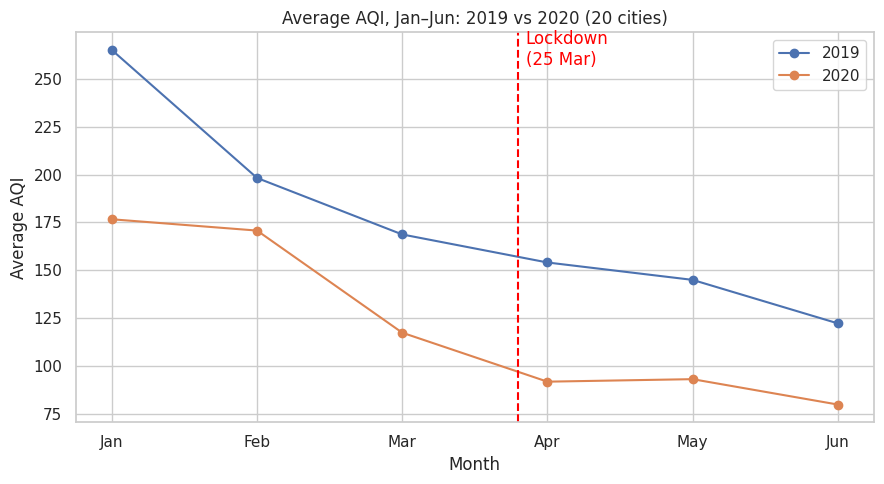

In [35]:
# Compare Jan-Jun of 2019 and 2020, only for cities that have data in both years
h = df[(df['Month'] <= 6) & (df['Year'].isin([2019, 2020]))]
both_years = h.groupby('City')['Year'].nunique()
h = h[h['City'].isin(both_years[both_years == 2].index)]
cmp = h.pivot_table(index='Month', columns='Year', values='AQI', aggfunc='mean')

plt.figure(figsize=(9,5))
plt.plot(cmp.index, cmp[2019], marker='o', label='2019')
plt.plot(cmp.index, cmp[2020], marker='o', label='2020')
plt.axvline(3.8, color='red', ls='--'); plt.text(3.85, cmp.values.max()*0.97, 'Lockdown\n(25 Mar)', color='red')
plt.xticks(range(1,7), ['Jan','Feb','Mar','Apr','May','Jun'])
plt.xlabel('Month'); plt.ylabel('Average AQI')
plt.title(f'Average AQI, Jan–Jun: 2019 vs 2020 ({len(both_years[both_years==2])} cities)')
plt.legend(); plt.tight_layout(); plt.show()

**Why:** The lockdown stopped most traffic and industry in 2020. It acts like a natural experiment, and we also use the same months of 2019 as a fair comparison. This is a good base for a hypothesis test later.
**What it shows:** The 2020 line is **below the 2019 line in every month**. Before the lockdown, 2020 was already 14–33% lower (Jan–Mar); during the lockdown months (Apr–Jun) it was 34–40% lower. So the lockdown probably helped, but 2020 was already cleaner in January, which means **the lockdown is not the only reason**. A hypothesis test is needed to be sure.

## B9. State-level view (using station data)

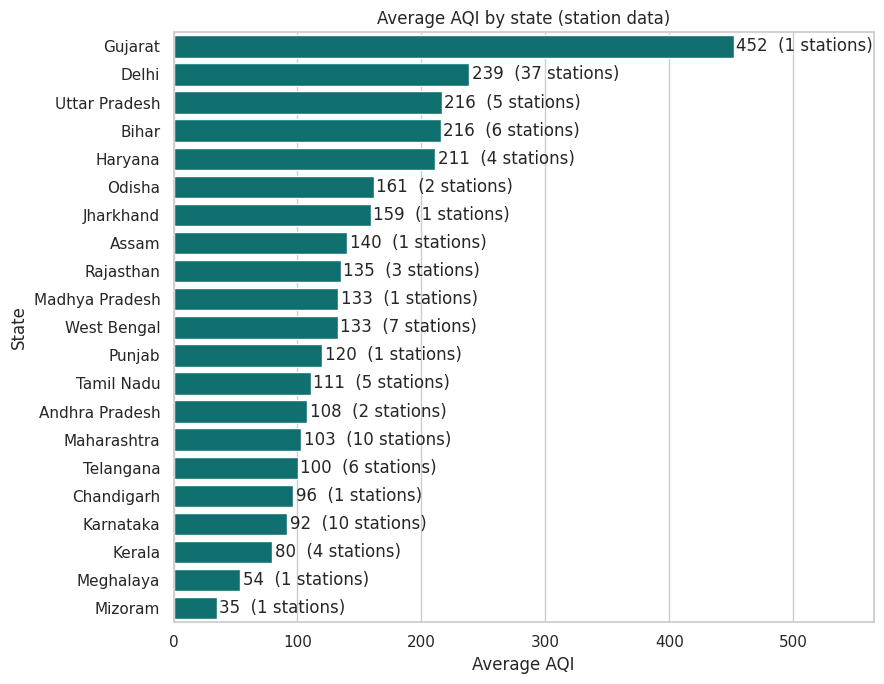

In [36]:
state = sd.groupby('State').agg(avg_AQI=('AQI', 'mean'), stations=('StationId', 'nunique'), days=('AQI', 'count')).sort_values('avg_AQI', ascending=False)
plt.figure(figsize=(9,7))
ax = sns.barplot(x=state['avg_AQI'], y=state.index, color='teal')
for i, (v, n) in enumerate(zip(state['avg_AQI'], state['stations'])):
    ax.text(v + 2, i, f'{v:.0f}  ({n} stations)', va='center')
plt.xlim(0, state['avg_AQI'].max() * 1.25)
plt.xlabel('Average AQI'); plt.ylabel('State')
plt.title('Average AQI by state (station data)')
plt.tight_layout(); plt.show()

**Why:** `station_day.csv` has much more detail (many stations per city), so we use it to check if the state-level picture agrees with the city-level picture.
**What it shows:** **Gujarat is at the top (about 452) but it has only 1 station**, so this one Ahmedabad station is responsible for the extreme values we saw earlier. After Gujarat come Delhi, Uttar Pradesh, Bihar and Haryana (all above 200), and southern states, Meghalaya and Mizoram are lowest. So the city-level and station-level files tell the same story. The number of stations per state differs a lot (1 to 37), so states with 1 station should be read with care.

# CONCLUSION – What we learned from pre-processing and EDA

1. **Data quality:** The data has no duplicates or negative values, but a lot is missing (Xylene 61%, PM10 38%, NH3 35%, AQI 16%) because many stations do not have every sensor. We dropped Xylene and rows without AQI, and filled the rest using the city-month median. We kept the real outliers.
2. **Data problems to remember:** The data is highly **right-skewed** (log transform fixes this), the coverage is **unbalanced** (cities start in different years and 2020 is half a year), and **Ahmedabad's CO is abnormally high**, which makes its AQI the highest. Ahmedabad must be handled separately in later analysis.
3. **What drives AQI:** **PM2.5 and PM10 are the main drivers** (correlation about 0.89–0.90 once Ahmedabad is removed). CO looks important (0.68) only because of Ahmedabad (0.30 without it). NOx is closely linked with NO/NO2, so we must be careful with repeated information in regression. Filling the missing PM10 values weakened its correlation (0.90 to 0.74), so the model part should treat PM10 carefully.
4. **Where and when pollution is worst:** North Indian cities (Delhi, Patna, Gurugram, Lucknow) are the most polluted, southern and north-eastern cities the cleanest. Pollution peaks in **post-monsoon and winter (Oct–Jan)** and is lowest in the monsoon. Day of the week makes no real difference.
5. **Lockdown and next steps:** AQI in 2020 was lower than in 2019 in every month (14–33% lower before the lockdown, 34–40% lower during it), so the lockdown likely helped but is not the only reason. Season, region, city and lockdown are the most promising factors for our analysis questions and hypothesis tests, and AQI can be our target variable for the ML model.